# Task 1: Monte Carlo Simulations

N = 100,000 simulations.

## Authors: Javier Gonzalo & Mauricio Valdez

## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
from numpy import random
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Fixed Profit and Costs Calculations


In [49]:
# Calculate profit per client

client_profit_per_year = 7*12   #7€/month × 12 months  (from value tree) since we take in-house strategy as baseline

# Calculate fixed costs
ih_fm_costs= 7_500 + 12_000 * 12   # training + flat and phone
out_fm_costs = 6_000 + 1_000 * 12    # training + third platform fees
cb_fm_costs  = 2_000 + 640 * 12      # training + maintenance + GPU


## 3. Simulate Distributions

In [50]:
N = 100_000

# In-House options
ih_tickets      = np.random.normal(8000, 800, N)
ih_cost_ticket  = np.random.normal(3.45, 0.5, N)         
ih_churn        = np.random.beta(2, 18, N)                             
ih_revenue      = ih_tickets * (1 - ih_churn) * client_profit_per_year
ih_total_cost   = ih_cost_ticket * ih_tickets + ih_fm_costs
ih_emv          = ih_revenue - ih_total_cost

# Outsource options
out_tickets     = np.random.normal(8000, 800, N)
out_cost_ticket = np.random.normal(1.31, 0.25, N)
out_churn       = np.random.beta(4, 16, N)                             
out_revenue     = out_tickets * (1 - out_churn) * client_profit_per_year
out_total_cost  = out_cost_ticket * out_tickets + out_fm_costs
out_emv         = out_revenue - out_total_cost

# Chatbot options
cb_tickets      = np.random.normal(8000, 800, N)
cb_cost_ticket  = np.random.normal(1.35, 0.3, N)        
cb_success_rate = np.random.beta(8.5, 1.5, N)                              
cb_churn        = np.random.beta(1.6, 18.4, N)                         
cb_revenue      = cb_tickets * cb_success_rate * (1 - cb_churn) * client_profit_per_year
cb_total_cost   = cb_cost_ticket * cb_tickets + cb_fm_costs
cb_emv          = cb_revenue - cb_total_cost


## 4. Simultation

In [77]:
simulation_results = pd.DataFrame({
    'Strategy':  ['In-House', 'Outsource', 'Chatbot'],
    'Mean EMV (€)':  [ih_emv.mean(), out_emv.mean(), cb_emv.mean()],
    'Std Dev (€)':   [ih_emv.std(),  out_emv.std(),  cb_emv.std()],
}).round()

display('Monte-Carlo Simulation Results', simulation_results)

'Monte-Carlo Simulation Results'

,Strategy,Mean EMV (€),Std Dev (€)
0,In-House,425492.0,72678.0
1,Outsource,508750.0,79043.0
2,Chatbot,504954.0,91192.0


## 5. Visualisations

In [59]:
data = {'In-House': ih_emv, 'Outsource': out_emv, 'Chatbot': cb_emv}
COLORS = {'In-House':'blue', 'Outsource': 'green', 'Chatbot': 'red'}

data2= pd.DataFrame(data)
print(data2)

            In-House      Outsource        Chatbot
0      392680.874312  444775.413117  611811.235704
1      389245.759210  585168.602972  559688.890297
2      513279.190873  589493.610633  426116.895720
3      445469.492227  412412.152772  479193.223990
4      444453.570148  513341.070154  530612.303309
...              ...            ...            ...
99995  358336.258952  373910.827818  541774.052794
99996  355215.749647  543504.299595  525357.263191
99997  483145.682382  432621.054698  527501.364294
99998  483190.384937  523799.792276  294941.697825
99999  532735.053503  503790.078108  562655.191609

[100000 rows x 3 columns]


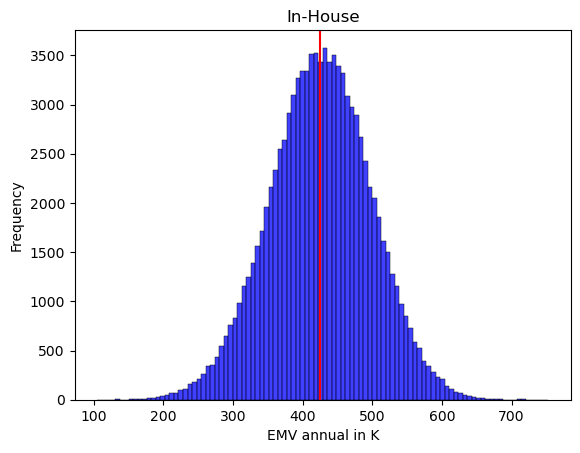

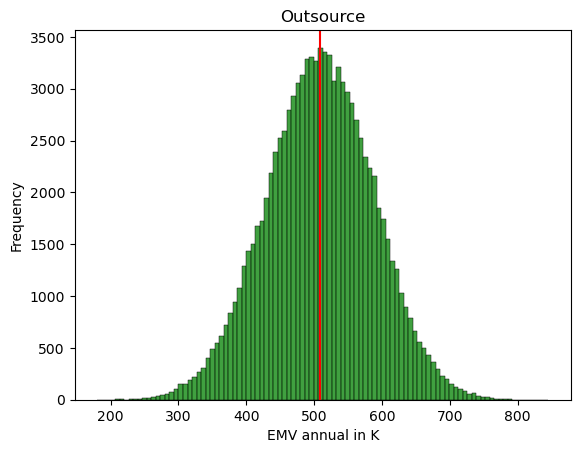

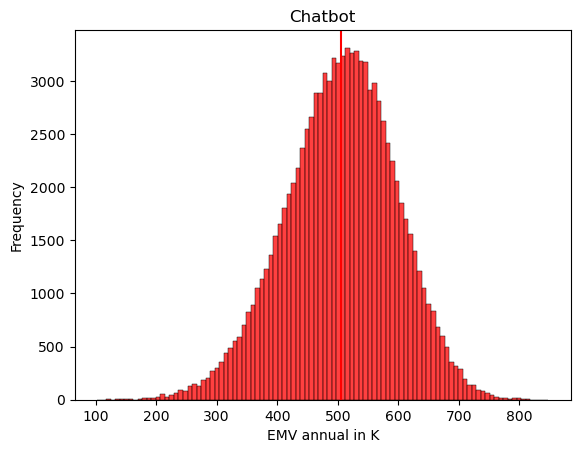

In [53]:
for names, values in data.items():
    sns.histplot(x=values/1000, bins= 100, color=COLORS[names])
    plt.axvline(values.mean()/1000, color='red')
    plt.title(names)
    plt.xlabel('EMV annual in K')
    plt.ylabel('Frequency')
    plt.show()

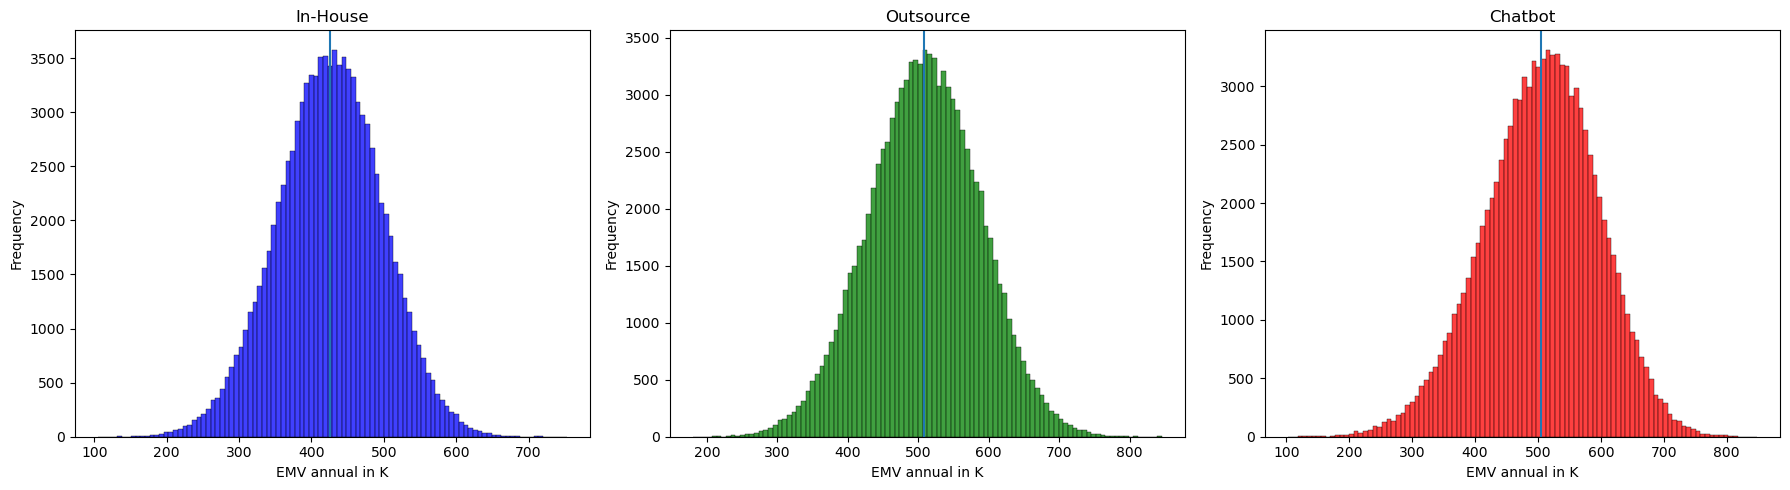

In [54]:
# https://www.perplexity.ai/search/i-have-this-python-code-but-i-Oi3XZPSmQHy1jBBXZQNwiQ

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (names, values) in zip(axes, data.items()):
    sns.histplot(values/1000, bins=100, color=COLORS[names], ax=ax)
    ax.axvline(values.mean()/1000)
    ax.set_title(names)
    ax.set_xlabel('EMV annual in K')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

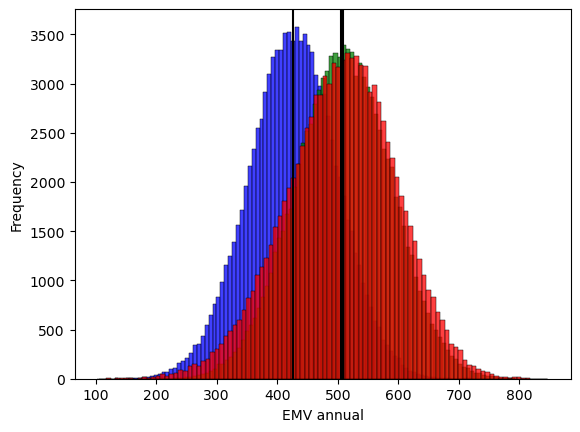

In [86]:
data = {'In-House': ih_emv, 'Outsource': out_emv, 'Chatbot': cb_emv}

for names, values in data.items():
    sns.histplot(x=values/1000, bins=100, color=COLORS[names])
    plt.axvline(values.mean()/1000, color= 'black')
    plt.xlabel('EMV annual')
    plt.ylabel('Frequency')

Text(0, 0.5, 'EMV')

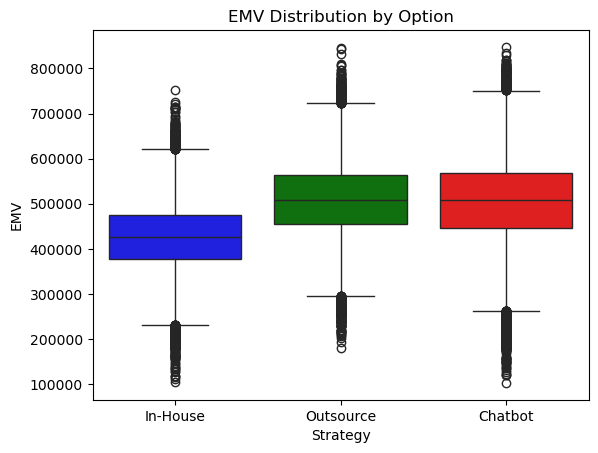

In [98]:
sns.boxplot(data=data, palette=['blue', 'green', 'red'])
plt.title('EMV Distribution by Option')
plt.xlabel('Strategy')
plt.ylabel('EMV')

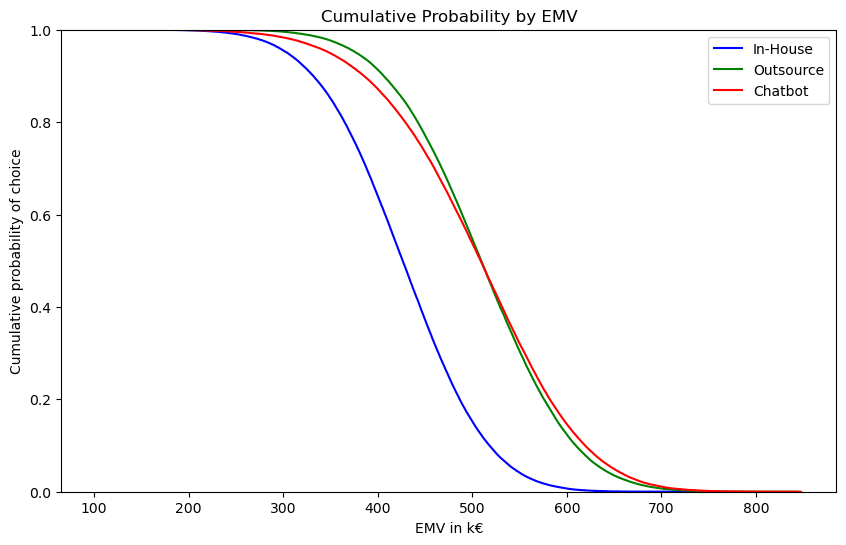

In [94]:
# https://www.perplexity.ai/search/dame-una-funcion-con-la-que-pu-crtU2n2oRY.AQBNcDbDKtg?sm=d

fig, ax = plt.subplots(figsize= (10,6))

for names, values in data.items():
    sns.ecdfplot(x=values/1000, complementary=True, color=COLORS[names],label=names)
ax.set(title='Cumulative Probability by EMV', xlabel='EMV in k€', ylabel='Cumulative probability of choice')
plt.legend()

## 6. Best Strategy & Conclusion

In [74]:
simulation_results = pd.DataFrame({
    'Strategy':  ['In-House', 'Outsource', 'Chatbot'],
    'Mean (€)':  [ih_emv.mean(), out_emv.mean(), cb_emv.mean()],
    '1 Standard Deviation (€)':   [ih_emv.std(),  out_emv.std(),  cb_emv.std()],
}).round()

display('Monte-Carlo Simulation Results', simulation_results)

'Monte-Carlo Simulation Results'

,Strategy,Mean (€),1 Standard Deviation (€)
0,In-House,425492.0,72678.0
1,Outsource,508750.0,79043.0
2,Chatbot,504954.0,91192.0


If we want to maximize the value with less risk expected = Outsource

If we have high tolerance to risk, want an optimist view = Chatbot


As a change based on these results, we would have 1 engineer every month for 5k and the other one only for training (1 a year). This would decrease the cost per ticket and would therefore maximize the mean profit even more, making the chatbot the most valuable option.